BANK LOAN DATASET
   Income  Credit_Score  Loan_Amount  Employment_Years Loan_Status
0   50000           750       200000                 8    Approved
1   30000           580       300000                 2    Rejected
2   80000           800       250000                10    Approved
3   25000           520       400000                 1    Rejected
4   90000           820       200000                12    Approved

ACTUAL LOAN STATUS:
['Approved', 'Rejected', 'Approved', 'Rejected', 'Rejected', 'Approved']

PREDICTED LOAN STATUS:
['Approved', 'Rejected', 'Approved', 'Rejected', 'Rejected', 'Approved']

Model Accuracy: 100.0 %


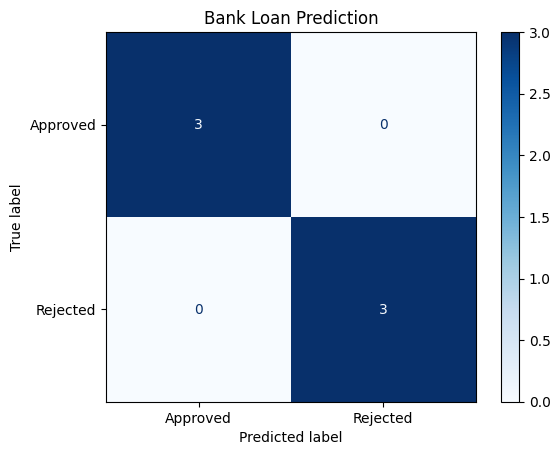


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Approved       1.00      1.00      1.00         3
    Rejected       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6


NEW APPLICANT DETAILS
 Income  Credit_Score  Loan_Amount  Employment_Years
  65000           750       200000                 7
Predicted Loan Status: Approved

Program executed successfully!


In [20]:

# Bank Loan Prediction Using Naive Bayes

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Step 1: Create a sample bank loan dataset
data = {
    "Income": [
        50000, 30000, 80000, 25000, 90000,
        45000, 70000, 20000, 85000, 35000,
        60000, 28000, 95000, 40000, 75000,
        55000, 32000, 82000, 27000, 88000,
        65000, 42000, 72000, 23000, 98000,
        48000, 78000, 31000, 92000, 38000
    ],
    "Credit_Score": [
        750, 580, 800, 520, 820,
        650, 760, 500, 790, 600,
        720, 540, 830, 680, 770,
        740, 560, 810, 510, 800,
        730, 670, 780, 530, 850,
        640, 790, 570, 840, 620
    ],
    "Loan_Amount": [
        200000, 300000, 250000, 400000, 200000,
        350000, 220000, 450000, 180000, 380000,
        230000, 420000, 190000, 300000, 210000,
        240000, 390000, 200000, 430000, 220000,
        250000, 320000, 210000, 440000, 180000,
        340000, 230000, 410000, 190000, 360000
    ],
    "Employment_Years": [
        8, 2, 10, 1, 12,
        5, 9, 1, 11, 3,
        7, 2, 13, 4, 8,
        6, 2, 10, 1, 12,
        7, 4, 9, 1, 14,
        5, 9, 2, 13, 3
    ],
    "Loan_Status": [
        "Approved", "Rejected", "Approved", "Rejected",
        "Approved", "Rejected", "Approved", "Rejected",
        "Approved", "Rejected", "Approved", "Rejected",
        "Approved", "Rejected", "Approved", "Approved",
        "Rejected", "Approved", "Rejected", "Approved",
        "Approved", "Rejected", "Approved", "Rejected",
        "Approved", "Rejected", "Approved", "Rejected",
        "Approved", "Rejected"
    ]
}

df = pd.DataFrame(data)

print("BANK LOAN DATASET")
print(df.head())

# Step 2: Separate input features and target
X = df[[
    "Income", "Credit_Score",
    "Loan_Amount", "Employment_Years"
]]
y = df["Loan_Status"]

# Step 3: Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Create and train the Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Step 5: Predict loan status
y_pred = model.predict(X_test)

print("\nACTUAL LOAN STATUS:")
print(y_test.tolist())

print("\nPREDICTED LOAN STATUS:")
print(y_pred.tolist())

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 7: Display confusion matrix
labels = ["Approved", "Rejected"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(cmap="Blues")
plt.title("Bank Loan Prediction")
plt.show()

# Step 8: Classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test, y_pred,
    labels=labels,
    zero_division=0
))

# Step 9: Predict for a new applicant
new_applicant = pd.DataFrame({
    "Income": [65000],
    "Credit_Score": [750],
    "Loan_Amount": [200000],
    "Employment_Years": [7]
})

prediction = model.predict(new_applicant)[0]

print("\nNEW APPLICANT DETAILS")
print(new_applicant.to_string(index=False))
print("Predicted Loan Status:", prediction)

print("\nProgram executed successfully!")
